# Capacity-constrained QUBO airline recovery

An executed, fixed-seed experiment on the authorized de-identified catalog. A matched-population ablation separates search refinement from additional connecting routes and cabin alternatives. Both variants share inventory, scoring weights and recovery constraints; the client performs the external industry comparison.

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, SVG
from experiment import ROOT, CONFIG, run_experiment, allocation_table

print("Execution: classical neal simulated annealing + separately audited classical refinement")
print("Fixed seeds:", CONFIG["seeds"])
print("Recovery policy:", CONFIG["connection_generation"])

Execution: classical neal simulated annealing + separately audited classical refinement
Fixed seeds: [7, 11, 29, 47, 73]
Recovery policy: {'min_connection_minutes': 45, 'max_layover_minutes': 1080, 'recovery_minutes': 4320, 'max_legs': 3, 'path_budget_per_journey': 20000}


## Formulation and acceptance

Each PNR selects one route or unassignment. Integer seat inequalities use bounded slack:

$$E=\sum_i c_i x_i+u\sum_p d_p+\lambda\sum_p(\sum_{i\in p}x_i+d_p-1)^2+\lambda\sum_r(\sum_i n_{ir}x_i+s_r-C_r)^2.$$

$\lambda>\sum|c_i|+\sum_p|u|$ certifies feasible global ground states. Finite annealing and decomposition remain heuristic. Accepted refinement moves preserve passenger counts and improve S3; exact rational dual certificates bound attainable allocation.

In [3]:
report = run_experiment(ROOT / "artifacts/notebook")
print("ALLOCATION AND RUNTIME BY CATALOG AND SEED")
display(allocation_table(report))
print("END-TO-END TIMING")
display(pd.DataFrame([report["timing"]]))
print("CANDIDATE COVERAGE AND CURATION")
display(pd.DataFrame([report["connection_audit"]]))
print("EXACT CAPACITY CEILINGS — EXPANDED CATALOG")
display(pd.DataFrame(report["capacity_upper_bounds"]).T)

seed 7: original 57.5983% PNR/47.4624% passengers; expanded 72.1678% PNR/61.2333% passengers; zero capacity and route-policy violations


seed 11: original 57.6506% PNR/47.5131% passengers; expanded 72.1678% PNR/61.3094% passengers; zero capacity and route-policy violations


seed 29: original 57.5591% PNR/47.5554% passengers; expanded 72.1939% PNR/61.3348% passengers; zero capacity and route-policy violations


seed 47: original 57.6245% PNR/47.3778% passengers; expanded 72.2070% PNR/61.2079% passengers; zero capacity and route-policy violations


seed 73: original 57.5853% PNR/47.3947% passengers; expanded 72.1939% PNR/61.3433% passengers; zero capacity and route-policy violations


Matplotlib is building the font cache; this may take a moment.


... (4 outputs left out)

CANDIDATE COVERAGE AND CURATION


,original_options,retained_original_options,removed_original_options,removed_reasons,added_options,added_leg_counts,total_options,base_feature_maximum_absolute_error,policy,seconds,scope
0,57963,57830,133,{'late_recovery': 133},381315,"{1: 20358, 2: 247205, 3: 113752}",439145,2.220446e-16,"{'max_layover_minutes': 1080, 'min_connection_...",7.991091,All supplied flights and feasible cabin patter...


EXACT CAPACITY CEILINGS — EXPANDED CATALOG


,rational_upper_bound,integer_upper_bound,denominator,fractional_upper_bound_percent,integer_upper_bound_percent,seventy_percent_possible
pnrs,156791/28,5599,7653,73.169719,73.160852,True
passengers,7437,7437,11822,62.908137,62.908137,False


## Interpretation

Resource counts are logical estimates. Allocation gains include candidate expansion and classical repair, with no quantum-hardware, speedup or measured satisfaction claim. Service proxies expose connection, journey-time and cabin tradeoffs. Airport-specific transfer rules, commercial costs and original-journey anomalies remain external limitations.

S3 AND SERVICE PROXIES AMONG ALLOCATED BOOKINGS


,catalog,seed,S3_objective,captured_normalized_CVM,mean_connections,mean_journey_minutes,passenger_weighted_mean_journey_minutes,mean_recovery_minutes,downgraded_pnrs,upgraded_pnrs,mixed_cabin_pnrs,direct_pnrs,connecting_pnrs,interpretation
0,Original routes,7,35391.867370,1106.863960,0.590971,457.509301,461.606844,2203.538793,181,1309,767,1810,2598,Observable service proxies; no measured custom...
1,Original routes,11,35361.510683,1101.638282,0.587489,456.253173,460.291081,2211.599501,181,1313,772,1828,2584,Observable service proxies; no measured custom...
2,Original routes,29,35427.289901,1099.322625,0.583201,453.163224,458.127179,2210.906016,182,1316,775,1842,2563,Observable service proxies; no measured custom...
3,Original routes,47,35372.835186,1103.084673,0.590023,457.534014,461.654705,2208.500454,181,1305,766,1816,2594,Observable service proxies; no measured custom...
4,Original routes,73,35402.722102,1100.984026,0.587928,459.486499,463.048902,2204.189471,177,1306,751,1823,2584,Observable service proxies; no measured custom...
5,Expanded routes,7,24837.488153,1337.052284,0.676625,549.016658,553.139246,3079.711027,472,2024,433,1908,3615,Observable service proxies; no measured custom...
6,Expanded routes,11,24859.152370,1336.780670,0.676806,549.223067,551.614514,3083.043455,475,2029,444,1908,3615,Observable service proxies; no measured custom...
7,Expanded routes,29,24831.395296,1337.769569,0.676380,550.498462,553.152255,3070.997466,471,2046,444,1904,3621,Observable service proxies; no measured custom...
8,Expanded routes,47,24819.374019,1339.498325,0.674267,545.861383,551.301962,3072.522258,464,2038,451,1914,3612,Observable service proxies; no measured custom...
9,Expanded routes,73,24827.856507,1335.605773,0.675113,544.140271,547.043988,3072.216833,479,2048,465,1917,3608,Observable service proxies; no measured custom...


QUBO RESOURCES; CLASSICAL REFINEMENT IS REPORTED SEPARATELY IN JSON


,catalog,seed,chunks,peak_variables,peak_couplers,maximum_ising_dynamic_range,raw_zero_residual_samples,total_samples,summed_raw_chunk_overloads
0,Original routes,7,319,128,1093,281728.373501,14041,15312,0
1,Original routes,11,322,128,1126,302853.466782,13979,15456,0
2,Original routes,29,320,128,1069,270145.579459,13756,15360,0
3,Original routes,47,320,128,1074,295852.233525,13944,15360,0
4,Original routes,73,322,128,1277,259652.645906,14035,15456,0
5,Expanded routes,7,370,128,1543,56833.638972,16286,17760,0
6,Expanded routes,11,370,128,1543,34894.911299,16268,17760,0
7,Expanded routes,29,370,128,1382,52146.480536,15912,17760,0
8,Expanded routes,47,369,128,1543,50954.452188,16368,17712,0
9,Expanded routes,73,370,128,1538,42905.186094,16217,17760,0


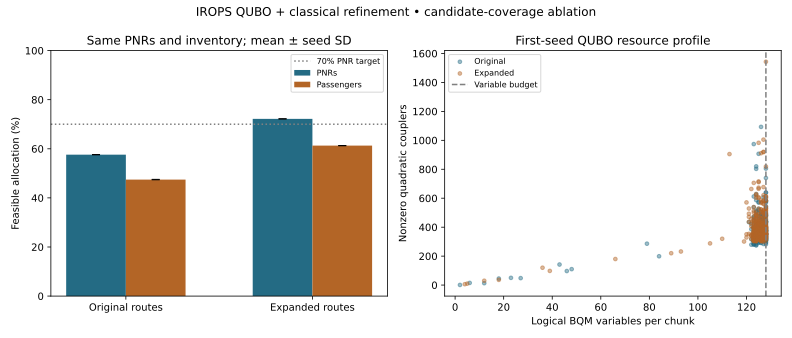

In [4]:
print("S3 AND SERVICE PROXIES AMONG ALLOCATED BOOKINGS")
quality = []
resources = []
for label, rows in [("Original routes", report["controls"]), ("Expanded routes", report["runs"])]:
    for row in rows:
        quality.append({"catalog": label, "seed": row["seed"], "S3_objective": row["objective"],
                        "captured_normalized_CVM": row["captured_cvm"], **row["service_proxies"]})
        resources.append({"catalog": label, "seed": row["seed"], **row["resources"]})
display(pd.DataFrame(quality))
print("QUBO RESOURCES; CLASSICAL REFINEMENT IS REPORTED SEPARATELY IN JSON")
display(pd.DataFrame(resources))
display(SVG(filename=str(ROOT / "artifacts/notebook/allocation_resources.svg")))